,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
ABEV3.SA,1245.0,0.000253,0.014450,-0.078537,-0.007797,0.000000,0.007358,0.153047,0.955297,11.757297
BBDC4.SA,1245.0,0.000396,0.019870,-0.216986,-0.008992,0.000549,0.009804,0.156442,-1.327514,24.182176
EGIE3.SA,1245.0,0.000324,0.013417,-0.106853,-0.007029,0.000493,0.007874,0.054012,-0.451753,4.956820
ITUB4.SA,1245.0,0.000933,0.015414,-0.136646,-0.008092,0.000707,0.009692,0.103725,-0.082518,7.420051
LREN3.SA,1245.0,-0.000180,0.029452,-0.336077,-0.017274,-0.000465,0.016692,0.153912,-1.061594,14.380607
PETR4.SA,1245.0,0.001711,0.019812,-0.091994,-0.008342,0.001674,0.012505,0.081884,-0.309909,2.628950
VALE3.SA,1245.0,0.000397,0.018356,-0.075913,-0.010065,0.000000,0.009141,0.103957,0.412203,2.301642
WEGE3.SA,1245.0,0.000449,0.019040,-0.115514,-0.009816,-0.000266,0.009518,0.104666,0.049151,4.685530


ABEV3.SA | pior dia: 2026-10-26 -0.079 | melhor dia: 2026-05-05 0.153
BBDC4.SA | pior dia: 2026-10-26 -0.217 | melhor dia: 2025-05-08 0.156
EGIE3.SA | pior dia: 2026-10-26 -0.107 | melhor dia: 2022-10-03 0.054
ITUB4.SA | pior dia: 2026-10-26 -0.137 | melhor dia: 2026-10-05 0.104
LREN3.SA | pior dia: 2026-10-26 -0.336 | melhor dia: 2026-10-05 0.154
PETR4.SA | pior dia: 2022-10-24 -0.092 | melhor dia: 2026-10-05 0.082
VALE3.SA | pior dia: 2021-11-03 -0.076 | melhor dia: 2022-11-11 0.104
WEGE3.SA | pior dia: 2025-04-30 -0.116 | melhor dia: 2024-07-31 0.105


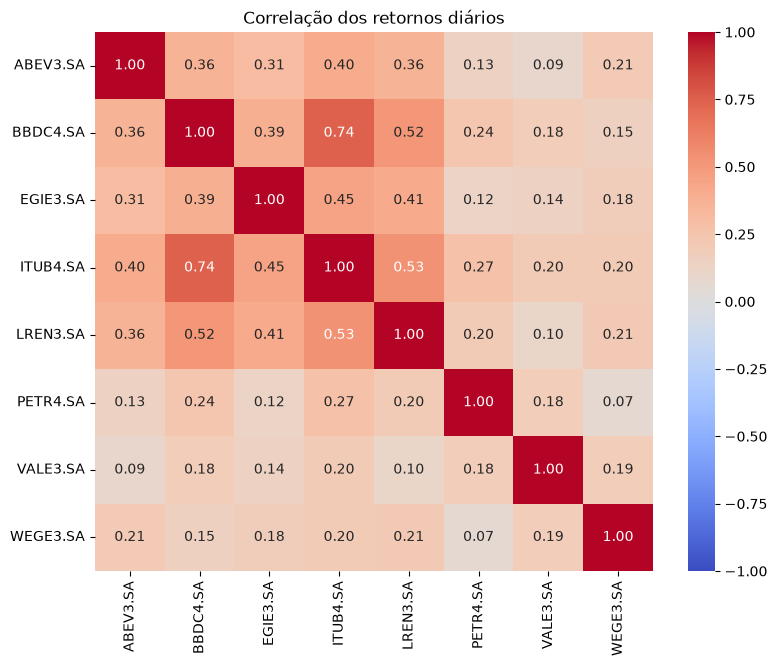

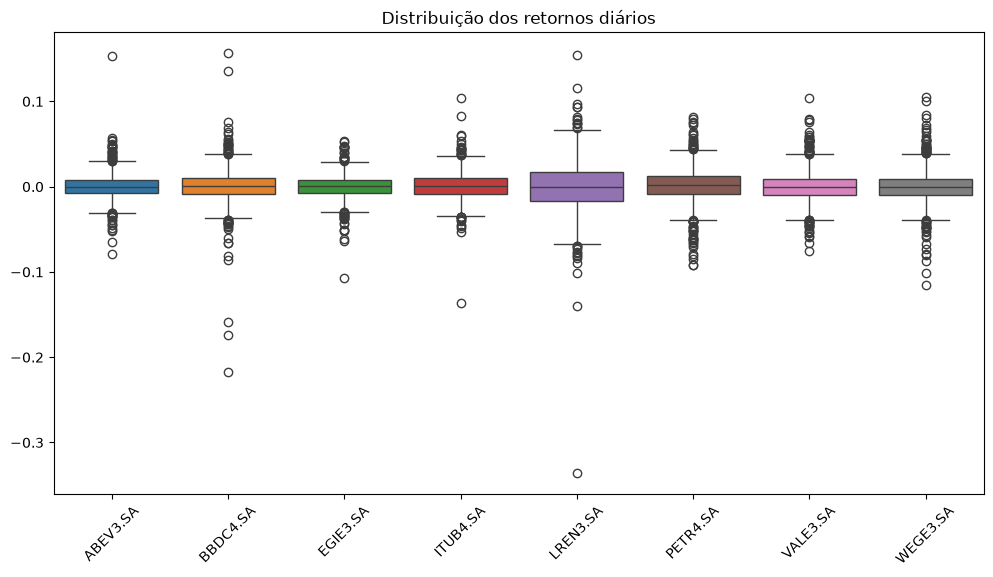

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

retornos = pd.read_csv("../data/processed/retornos.csv", index_col=0, parse_dates=True)

# Estatísticas descritivas dos retornos
resumo = retornos.describe().T
resumo["assimetria"] = retornos.skew()
resumo["curtose"] = retornos.kurt()
display(resumo)

for acao in retornos.columns:
    print(acao,
          "| pior dia:", retornos[acao].idxmin().date(), round(retornos[acao].min(), 3),
          "| melhor dia:", retornos[acao].idxmax().date(), round(retornos[acao].max(), 3))

# Correlação dos retornos
plt.figure(figsize=(9, 7))
sns.heatmap(retornos.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação dos retornos diários")
plt.show()

# Distribuição e outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=retornos)
plt.xticks(rotation=45)
plt.title("Distribuição dos retornos diários")
plt.show()

In [2]:
import numpy as np

ibov = pd.read_csv("../data/raw/ibovespa.csv", index_col=0, parse_dates=True)
ibov_ret = ibov.iloc[:, 0].pct_change().dropna()

data_evento = pd.Timestamp("2026-10-26")
print(f"Ibovespa em {data_evento.date()}: {ibov_ret.loc[data_evento]:.2%}")
display(retornos.loc[data_evento].map("{:.2%}".format))

# Sensibilidade: estatísticas com e sem o dia do choque
sem_evento = retornos.drop(data_evento)

comparacao = pd.DataFrame({
    "vol_diaria_com": retornos.std(),
    "vol_diaria_sem": sem_evento.std(),
    "curtose_com": retornos.kurt(),
    "curtose_sem": sem_evento.kurt(),
    "assimetria_com": retornos.skew(),
    "assimetria_sem": sem_evento.skew(),
}).round(3)
display(comparacao)



Ibovespa em 2026-10-26: -13.88%


ABEV3.SA     -7.85%
BBDC4.SA    -21.70%
EGIE3.SA    -10.69%
ITUB4.SA    -13.66%
LREN3.SA    -33.61%
PETR4.SA     -8.18%
VALE3.SA      4.01%
WEGE3.SA      4.21%
Name: 2026-10-26 00:00:00, dtype: str

,vol_diaria_com,vol_diaria_sem,curtose_com,curtose_sem,assimetria_com,assimetria_sem
ABEV3.SA,0.014,0.014,11.757,11.709,0.955,1.112
BBDC4.SA,0.020,0.019,24.182,16.113,-1.328,-0.346
EGIE3.SA,0.013,0.013,4.957,2.184,-0.452,-0.064
ITUB4.SA,0.015,0.015,7.420,3.024,-0.083,0.519
LREN3.SA,0.029,0.028,14.381,1.626,-1.062,0.128
PETR4.SA,0.020,0.020,2.629,2.530,-0.310,-0.265
VALE3.SA,0.018,0.018,2.302,2.323,0.412,0.411
WEGE3.SA,0.019,0.019,4.686,4.721,0.049,0.046


In [3]:
DIAS_UTEIS = 252

tabela = pd.DataFrame({
    "retorno_anual": (1 + retornos).prod() ** (DIAS_UTEIS / len(retornos)) - 1,
    "volatilidade_anual": retornos.std() * np.sqrt(DIAS_UTEIS),
})
tabela["retorno_por_risco"] = tabela["retorno_anual"] / tabela["volatilidade_anual"]

display(tabela.sort_values("retorno_por_risco", ascending=False).style.format("{:.2%}", subset=["retorno_anual", "volatilidade_anual"]).format("{:.2f}", subset=["retorno_por_risco"]))

,retorno_anual,volatilidade_anual,retorno_por_risco
PETR4.SA,46.40%,31.45%,1.48
ITUB4.SA,22.75%,24.47%,0.93
EGIE3.SA,6.07%,21.30%,0.28
WEGE3.SA,6.98%,30.22%,0.23
VALE3.SA,5.95%,29.14%,0.20
ABEV3.SA,3.85%,22.94%,0.17
BBDC4.SA,5.01%,31.54%,0.16
LREN3.SA,-14.60%,46.75%,-0.31
